# Entrega N°1 - Proyecto Final

Para este proyecto seleccionamos el dataset *"Estimation of Obesity Levels Based on Eating Habits and Physical Condition"*, publicado en el repositorio UCI. Reúne 2.111 registros de personas de Colombia, México y Perú, con 17 variables sobre sus datos físicos, hábitos de alimentación, actividad física y antecedentes familiares. Cada persona está clasificada en uno de siete niveles de peso, desde peso insuficiente hasta obesidad tipo III.

### Importar el Dataset del repositorio de UCI

In [4]:
# pip install ucimlrepo

from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544) 
  
# data (as pandas dataframes) 
X = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features 
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets 

### Librerías

In [6]:
# !pip install -q imbalanced-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Apariencia de tablas y gráficas
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

# Semilla para que todos obtengamos los mismos resultados
SEMILLA = 20
np.random.seed(SEMILLA)

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | seaborn 0.13.2


### Visualización de los datos

In [12]:
dataset = pd.concat([X, y], axis=1)
print("Dimensiones:", dataset.shape)
dataset.head()

Dimensiones: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000,1.620,64.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,0.000,1.000,no,Public_Transportation,Normal_Weight
1,Female,21.000,1.520,56.000,yes,no,3.000,3.000,Sometimes,yes,3.000,yes,3.000,0.000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000,1.800,77.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,2.000,1.000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000,1.800,87.000,no,no,3.000,3.000,Sometimes,no,2.000,no,2.000,0.000,Frequently,Walking,Overweight_Level_I
4,Male,22.000,1.780,89.800,no,no,2.000,1.000,Sometimes,no,2.000,no,0.000,0.000,Sometimes,Public_Transportation,Overweight_Level_II


In [9]:
def resumen(df):
    # Ficha técnica por columna: tipo, nulos, cardinalidad y un ejemplo
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

In [13]:
resumen(dataset)

,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Gender,str,2111,0,0.000,2,Female
Age,float64,2111,0,0.000,1402,21.000
Height,float64,2111,0,0.000,1574,1.620
Weight,float64,2111,0,0.000,1525,64.000
family_history_with_overweight,str,2111,0,0.000,2,yes
FAVC,str,2111,0,0.000,2,no
FCVC,float64,2111,0,0.000,810,2.000
NCP,float64,2111,0,0.000,635,3.000
CAEC,str,2111,0,0.000,4,Sometimes
SMOKE,str,2111,0,0.000,2,no


### Visualizar Variables Categóricas

In [19]:
categoricas = dataset.select_dtypes(include=["string"]).columns
for col in categoricas:
    print(f"{col:32s} ({dataset[col].nunique()}) -> {list(dataset[col].unique())}")

Gender                           (2) -> ['Female', 'Male']
family_history_with_overweight   (2) -> ['yes', 'no']
FAVC                             (2) -> ['no', 'yes']
CAEC                             (4) -> ['Sometimes', 'Frequently', 'Always', 'no']
SMOKE                            (2) -> ['no', 'yes']
SCC                              (2) -> ['no', 'yes']
CALC                             (4) -> ['no', 'Sometimes', 'Frequently', 'Always']
MTRANS                           (5) -> ['Public_Transportation', 'Walking', 'Automobile', 'Motorbike', 'Bike']
NObeyesdad                       (7) -> ['Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II', 'Obesity_Type_I', 'Insufficient_Weight', 'Obesity_Type_II', 'Obesity_Type_III']


### Validación de relación entre IMC y Target

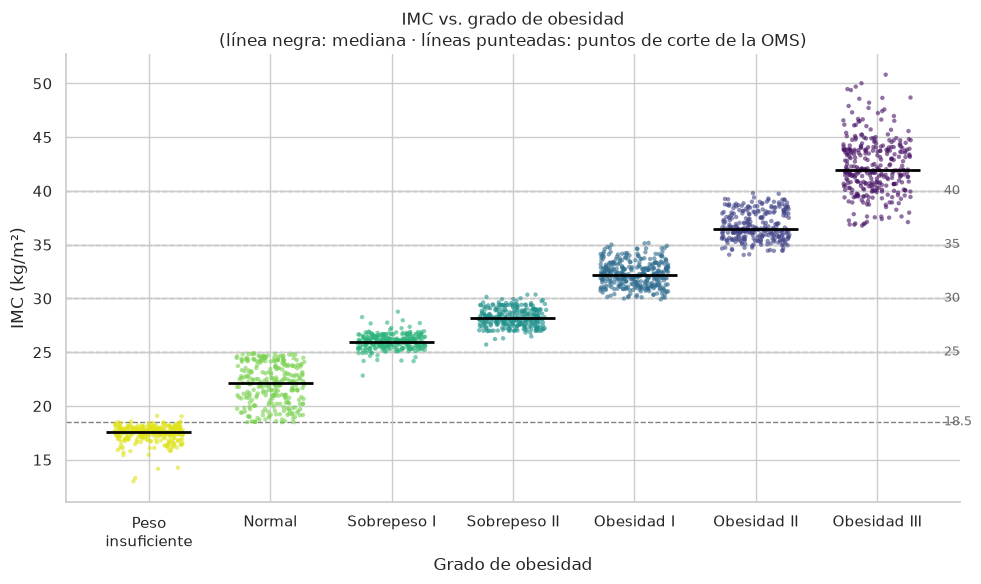

In [14]:
dataset['IMC'] = dataset['Weight'] / dataset['Height']**2

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
colores = plt.cm.viridis_r(np.linspace(0.05, 0.95, 7))

fig, ax = plt.subplots(figsize=(10, 6))
rng = np.random.default_rng(0)
for i, (clase, color) in enumerate(zip(orden, colores)):
    imc = dataset.loc[dataset['NObeyesdad'] == clase, 'IMC']
    x = i + rng.uniform(-0.28, 0.28, len(imc))   # dispersión horizontal para que no se encimen
    ax.scatter(x, imc, s=10, color=color, alpha=0.6, edgecolor='none')
    ax.hlines(imc.median(), i - 0.35, i + 0.35, color='black', linewidth=2)   # mediana

# Puntos de corte de la OMS
for v in [18.5, 25, 30, 35, 40]:
    ax.axhline(v, color='gray', linestyle='--', linewidth=1, zorder=0)
    ax.text(6.55, v, f'{v}', va='center', fontsize=9, color='dimgray')

ax.set_xticks(range(7), etiquetas)
ax.set_xlabel('Grado de obesidad')
ax.set_ylabel('IMC (kg/m²)')
ax.set_title('IMC vs. grado de obesidad\n(línea negra: mediana · líneas punteadas: puntos de corte de la OMS)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()